don't use Kasa method, better the generic one  
with it, can have uncertainty on the params  

### Generate points on a circle

In [16]:
import numpy as np

def generate_noisy_circle_points(n_points, radius=3, center=(5, 5), sigma=0.01, seed=42):
    """Generate noisy data points sampled from a circle.

    Parameters:
        n_points (int): Number of points to generate.
        radius (float): Radius of the circle.
        center (tuple): Coordinates (xc, yc) of the circle center.
        sigma (float): Standard deviation of the noise. (don't give)
        seed (int): Random seed for reproducibility. (don't give)

    Returns:
        x (ndarray): Noisy x-coordinates.
        y (ndarray): Noisy y-coordinates.
    """
    np.random.seed(seed)
    phi = np.random.uniform(0, 2 * np.pi, n_points)

    # if want points evenly spaced, use instead:
    # phi = np.linspace(0.0, 2.0 * np.pi, n_points)

    xc, yc = center

    x = xc + radius * np.cos(phi) + np.random.normal(0, sigma, n_points)
    y = yc + radius * np.sin(phi) + np.random.normal(0, sigma, n_points)

    return x, y

In [17]:
x, y = generate_noisy_circle_points(20)

### Kasa method

only good if points are evenly spaced  

In [18]:
def fit_circle(x, y, sigma):
    """Fit a series of data points to a circle.
    """
    n = len(x)
    # Refer coordinates to the mean values of x and y.
    x_m = np.mean(x)
    y_m = np.mean(y)
    u = x - x_m
    v = y - y_m
    # Calculate all the necessary sums.
    s_u = np.sum(u)
    s_uu = np.sum(u**2.0)
    s_uuu = np.sum(u**3.0)
    s_v = np.sum(v)
    s_vv = np.sum(v**2.0)
    s_vvv = np.sum(v**3.0)
    s_uv = np.sum(u * v)
    s_uuv = np.sum(u * u * v)
    s_uvv = np.sum(u * v * v)
    D = 2.0 * (s_uu * s_vv - s_uv**2.0)
    # Calculate the best-fit values.
    u_c = (s_vv * (s_uuu + s_uvv) - s_uv * (s_vvv + s_uuv)) / D
    v_c = (s_uu * (s_vvv + s_uuv) - s_uv * (s_uuu + s_uvv)) / D
    x_c = u_c + x_m
    y_c = v_c + y_m
    r = np.sqrt(u_c**2.0 + v_c**2.0 + (s_uu + s_vv) / n)
    # Calculate the errors---mind this is only rigorously valid
    # if the data points are equi-spaced on the circumference.
    sigma_xy = sigma * np.sqrt(2.0 / n)
    sigma_r = sigma * np.sqrt(1.0 / n)
    return  x_c, y_c, r, sigma_xy, sigma_r

In [19]:
# Uncertainty on x and y, assumed to be the same for all the
# data points, in both coordinates.
np.random.seed(1)
sigma = 0.05
x_c, y_c, r, sigma_xy, sigma_r = fit_circle(x, y, sigma)

In [20]:

print(f'x_c = {x_c:.3f} +/- {sigma_xy:.3f}')
print(f'y_c = {y_c:.3f} +/- {sigma_xy:.3f}')
print(f'r = {r:.3f} +/- {sigma_r:.3f}')


x_c = 4.995 +/- 0.016
y_c = 4.998 +/- 0.016
r = 3.003 +/- 0.011


## Normal circular fit

### Do the fit

In [21]:
## WHAT I NEED  

x=x
y=y
d = 0.01 # error on x and y

In [22]:
def chi2_circle (params, x, y, d): 
    xc, yc, R = params
    residuals = residuals = (((x - xc)**2 + (y - yc)**2 - R**2)**2) / ((x - xc)**2 + (y - yc)**2)
    return np.sum (residuals) / (4 * d**2)

In [23]:
import scipy.optimize as opt

# Fit circolare
initial_guess = [np.mean(x), np.mean (y), np.std(x)]
result = opt.minimize(chi2_circle, initial_guess, args=(x, y, d))
xc_fit, yc_fit, R_fit = result.x

### Extimate uncertainty params and chi

In [24]:
# Stuff for the bootstrap

x = x
y = y
d = d  # uncertainty on x and y  
chi2_circle = chi2_circle

In [25]:
# Stima degli errori con bootstrap (minimize the chi, since only have that, bc used that in the fit)

n_bootstrap = 1000
bootstrap_results = []
for _ in range(n_bootstrap):
    indices = np.random.choice(len(x),len(x), replace=True)
    x_boot, y_boot = x[indices], y[indices]
    res = opt.minimize(chi2_circle, initial_guess, args=(x_boot, y_boot, d))
    bootstrap_results.append(res.x)
    
bootstrap_results = np.array(bootstrap_results)
errors = np.std (bootstrap_results, axis=0)

In [26]:
### Compute chi square

ndof = len(x) -3 # gradi di libertà (n pintu) - parametri
chi2_red = result.fun/ ndof

In [27]:
# Stampa dei risultati
fit_summary = (
    f"Centro: XC = {xc_fit:.3f} ± {errors[0]:.3f}, YC = {yc_fit:.3f} ± {errors[1]:.3f}\n"
    f"Raggio: R = {R_fit:.3f} ± {errors[2]:.3f}\n"
    f"Gradi di libertà: {ndof}\n"
    f"Chi-quadro ridotto: {chi2_red:.3f}"
)

print("Fit Summary:")
print(fit_summary)

Fit Summary:
Centro: XC = 4.995 ± 0.002, YC = 4.998 ± 0.003
Raggio: R = 3.003 ± 0.002
Gradi di libertà: 17
Chi-quadro ridotto: 0.787


### Plot results

In [28]:
import matplotlib.pyplot as plt

In [29]:
### WHAT I NEED TO HAVE

xc_fit = xc_fit
yc_fit = yc_fit
R_fit = R_fit

# chi2_circle = chi2_circle    only for seconf plot, of chi vs R  

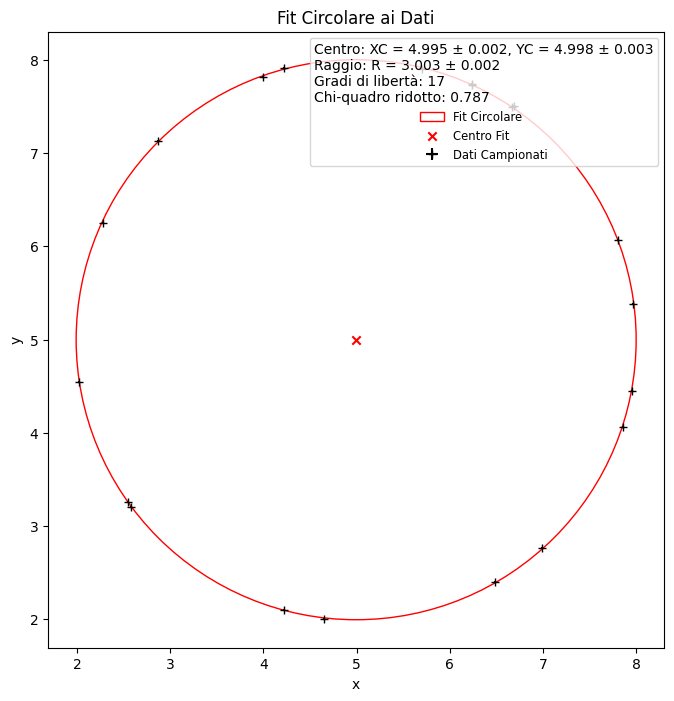

In [30]:
# Plot dei dati e del fit
fig, ax = plt.subplots(figsize=(8,8))
circle = plt.Circle((xc_fit, yc_fit), R_fit, color='r', fill=False, label='Fit Circolare')
ax.add_patch(circle)
ax.errorbar(x, y, xerr=d, yerr=d, fmt='k+', label='Dati Campionati') # Punti sperimentali in nero con croce
ax.scatter ([xc_fit], [yc_fit], color='red', marker='x', label='Centro Fit')
ax.set_aspect('equal')
plt.xlabel("x")
plt.ylabel("y")
plt.legend (title=fit_summary, loc='upper right', fontsize='small')
plt.title("Fit Circolare ai Dati")
plt.show()

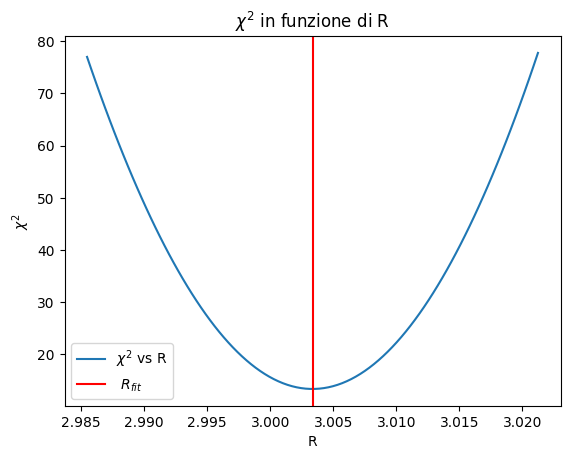

In [31]:
# Nuovo plot: Chi^2 in funzione di R 

R_values = np.linspace (R_fit - 10*errors [2], R_fit + 10*errors [2], 100)
chi2_values = [chi2_circle((xc_fit,yc_fit, R), x, y, d) for R in R_values]
plt.figure()
plt.plot(R_values, chi2_values, label=r"$ \chi^2$ vs R")
plt.axvline (R_fit, color='r', linestyle='-', label=r" $R_{fit}$")
plt.xlabel("R")
plt.ylabel(r"$\chi^2$")
plt.title(r"$\chi^2$ in funzione di R")
plt.legend ()
plt.show()